# Buscando la gira con gradiente descendente
Inteligencia Artificial - Facundo A. Lucianna - CEIA - FIUBA

En la notebook anterior modelamos la gira de **Los Auténticos Descendentes**: una gira es una permutación de las ciudades que arranca en Buenos Aires y termina en la Base Marambio, su costo son los km recorridos y sus vecinos son las giras que se obtienen con un movimiento 2-opt. Ahora vamos a usar estas herramientas para buscar la mejor gira con el algoritmo de **gradiente descendente**.

Empecemos con la Gira Federal, la de las 24 capitales:

In [1]:
import random

import matplotlib.pyplot as plt
import numpy as np

import gira

random.seed(42)

capitals = gira.load_cities("capitales")
distances = gira.distance_matrix(capitals)

---
## Implementando gradiente descendente

El algoritmo arranca desde una gira y, en cada paso, mira a todos sus vecinos y se mueve al que tiene menor costo. Cuando ninguno de los vecinos mejora la gira actual, se detiene: llegó a un mínimo. El algoritmo no mira más allá de los vecinos inmediatos, así que no tiene forma de saber si ese mínimo es el mejor de todos o solo el mejor de su vecindario.

Para elegir el mejor vecino no hace falta armar las 253 giras vecinas: alcanza con calcular cuánto cambia el costo con cada movimiento 2-opt usando `delta_cost()`, como vimos en la notebook anterior.

Veamos la implementación, prestando atención a los comentarios:

In [2]:
def gradient_descent(tour, distances, max_iterations=10_000):
    """
    Busca la mejor gira con gradiente descendente: en cada paso se mueve al mejor
    vecino y se detiene cuando ningún vecino mejora la gira actual.

    Args:
        tour (list): Gira desde donde arranca la búsqueda.
        distances (np.ndarray): Matriz de distancias entre ciudades.
        max_iterations (int, opcional): Cantidad máxima de pasos. Por defecto 10.000.

    Returns:
        tuple: (la gira encontrada, lista con el costo de la gira en cada paso)
    """
    moves = gira.obtain_moves(len(tour))
    history = [gira.cost_function(tour, distances)]

    for _ in range(max_iterations):
        # Cuánto cambia el costo con cada movimiento 2-opt posible
        deltas = [gira.delta_cost(tour, i, j, distances) for i, j in moves]

        # El movimiento que más reduce el costo
        best = int(np.argmin(deltas))

        # Si ningún vecino es mejor que la gira actual, llegamos a un mínimo
        if deltas[best] >= 0:
            break

        tour = gira.two_opt(tour, *moves[best])
        history.append(history[-1] + deltas[best])

    return tour, history

Arrancamos desde una gira al azar y aplicamos el algoritmo:

In [3]:
initial_tour = gira.init_state(capitals)
final_tour, history = gradient_descent(initial_tour, distances)

print("Costo de la gira inicial:", gira.format_km(history[0]))
print("Costo de la gira final:  ", gira.format_km(history[-1]))
print(f"Cantidad de pasos: {len(history) - 1}")

Costo de la gira inicial: 31.659 km
Costo de la gira final:   8.995 km
Cantidad de pasos: 19


Veamos cómo fue bajando el costo en cada paso:

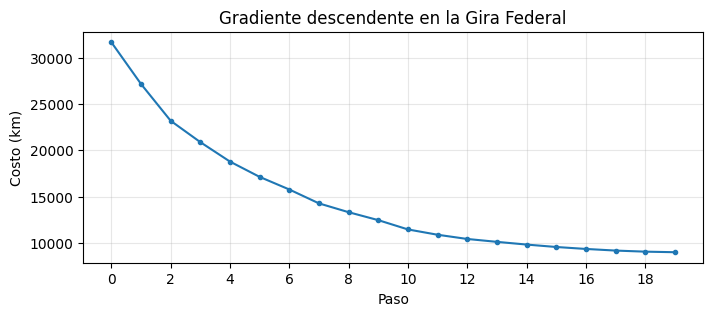

In [4]:
plt.figure(figsize=(8, 3))
plt.plot(history, marker="o", markersize=3)
plt.xticks(range(0, len(history), 2))
plt.xlabel("Paso")
plt.ylabel("Costo (km)")
plt.title("Gradiente descendente en la Gira Federal")
plt.grid(alpha=0.3)
plt.show()

Los primeros pasos son los que más reducen el costo: el algoritmo elige siempre el movimiento que más mejora, y al principio hay cruces enormes para deshacer. A medida que la gira se ordena, cada paso mejora menos, hasta que no queda ningún movimiento que la mejore.

Comparemos la gira inicial con la que encontró el algoritmo:

> 🗺️ **Nota**: La celda de abajo genera un mapa interactivo, donde se puede hacer zoom y ver el nombre y la fecha de cada ciudad al pasar el mouse. La dejamos sin ejecutar para que la notebook sea liviana. Si querés verlo, ejecutala. Debajo está la versión estática del mismo mapa.

In [ ]:
gira.plot_tours(
    capitals,
    {"Inicial": initial_tour, "Gradiente descendente": final_tour},
    distances,
    interactive=True,
)

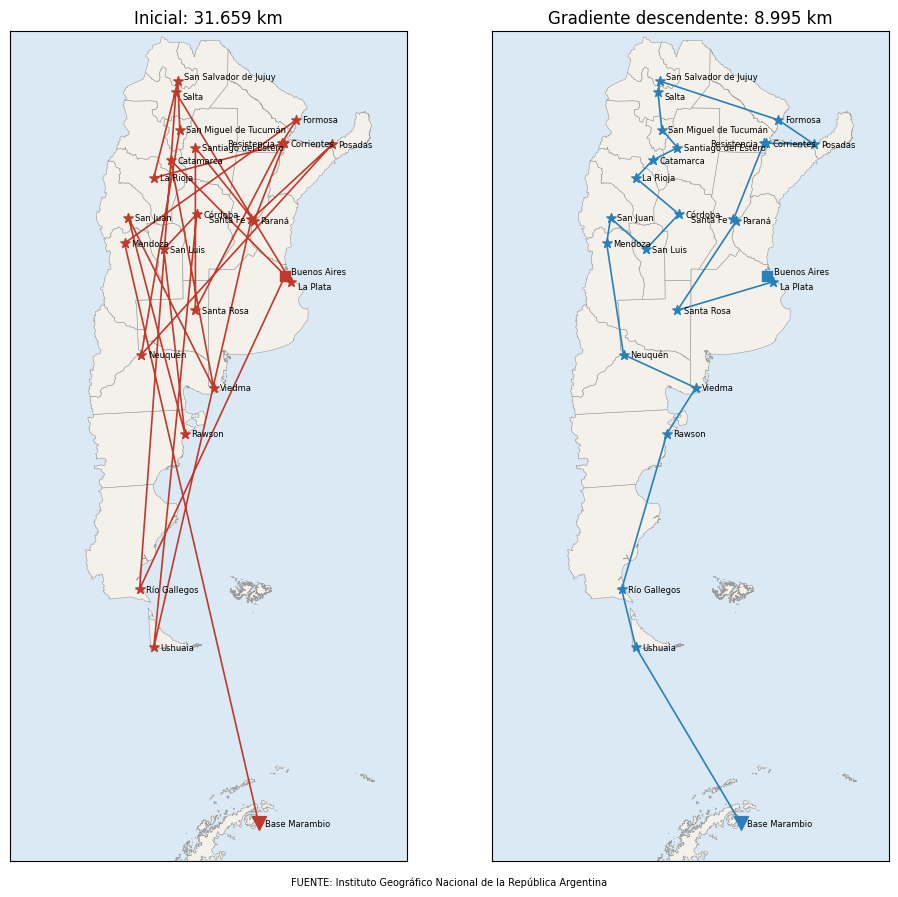

In [5]:
gira.plot_tours(
    capitals, {"Inicial": initial_tour, "Gradiente descendente": final_tour}, distances
)

La diferencia es enorme. La gira que encontró el algoritmo no tiene tramos que se crucen: si hubiera un cruce, habría un movimiento 2-opt que lo deshace y el algoritmo no se hubiera detenido.

---
## ¿Encontramos la mejor gira?

Que la gira no tenga cruces no quiere decir que sea la mejor. Gradiente descendente se detiene en el primer mínimo que encuentra, y ese mínimo depende de la gira desde donde arrancó. Probemos con 20 giras iniciales distintas:

In [6]:
results = []
for _ in range(20):
    tour, _ = gradient_descent(gira.init_state(capitals), distances)
    results.append((gira.cost_function(tour, distances), tour))

results.sort(key=lambda result: result[0])
print("Costo de las 20 giras encontradas, de menor a mayor:")
print([gira.format_km(cost) for cost, _ in results])

Costo de las 20 giras encontradas, de menor a mayor:
['8.410 km', '8.410 km', '8.410 km', '8.418 km', '8.418 km', '8.418 km', '8.426 km', '8.426 km', '8.426 km', '8.426 km', '8.508 km', '8.528 km', '8.528 km', '8.582 km', '8.598 km', '8.762 km', '8.769 km', '8.867 km', '8.995 km', '8.995 km']


Cada ejecución termina en una gira distinta. Todas son **mínimos locales**: ninguno de sus vecinos tiene menor costo, pero hay giras mejores en otras partes del espacio de búsqueda, a las que no se llega con un solo movimiento 2-opt. Comparemos la mejor y la peor de las 20:

> 🗺️ **Nota**: La celda de abajo genera un mapa interactivo, donde se puede hacer zoom y ver el nombre y la fecha de cada ciudad al pasar el mouse. La dejamos sin ejecutar para que la notebook sea liviana. Si querés verlo, ejecutala. Debajo está la versión estática del mismo mapa.

In [ ]:
gira.plot_tours(
    capitals,
    {"Mejor": results[0][1], "Peor": results[-1][1]},
    distances,
    interactive=True,
)

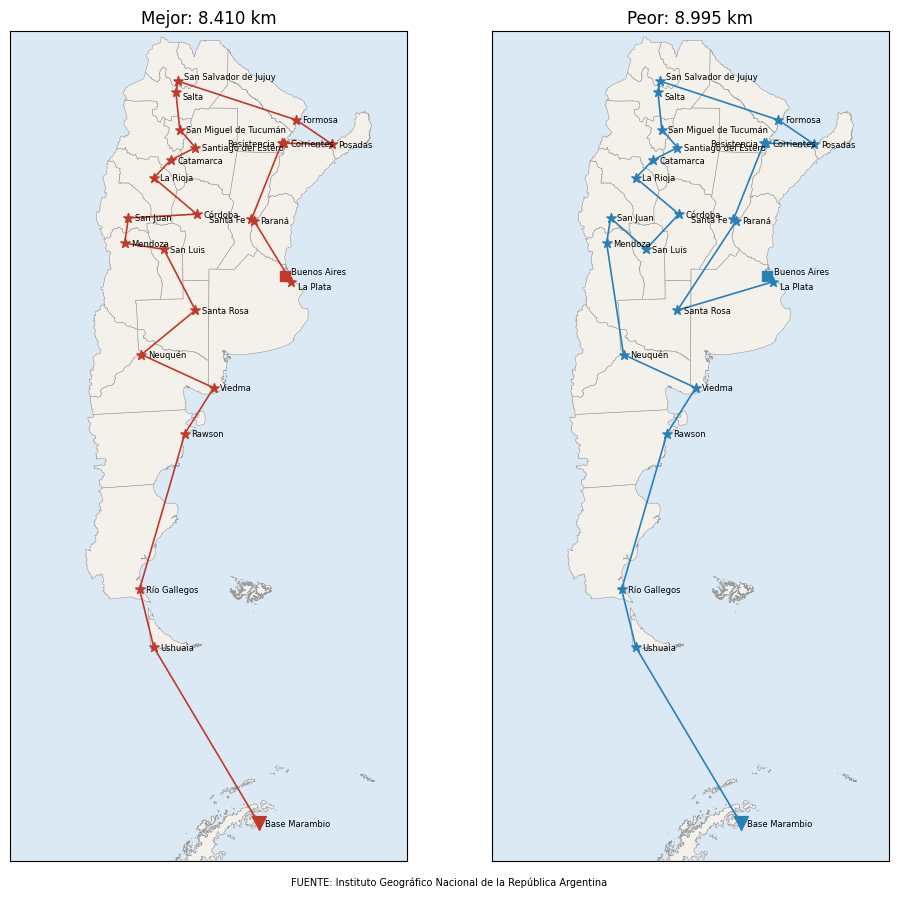

In [7]:
gira.plot_tours(capitals, {"Mejor": results[0][1], "Peor": results[-1][1]}, distances)

Las dos giras son razonables, y ninguna tiene cruces, pero toman decisiones distintas sobre el orden en que se recorren las regiones del país. Para pasar de una a la otra habría que cambiar muchos tramos a la vez, y cualquier camino de movimientos 2-opt entre ellas pasa por giras peores, que gradiente descendente nunca acepta.

Una estrategia simple para mejorar el resultado es justamente la que acabamos de hacer: ejecutar el algoritmo varias veces desde giras iniciales al azar y quedarnos con la mejor. Esto se conoce como **reinicio aleatorio** (*random restart*). Funciona bien cuando una ejecución es barata, como en la Gira Federal, pero no nos garantiza encontrar la mejor gira.

---
## Gradiente descendente estocástico

Una variante del algoritmo consiste en no moverse siempre al mejor vecino, sino a un vecino al azar entre todos los que mejoran la gira actual. La idea es que, al no ser tan codicioso, el algoritmo recorra caminos distintos y pueda terminar en otros mínimos.

In [8]:
def stochastic_gradient_descent(tour, distances, max_iterations=10_000):
    """
    Busca la mejor gira con gradiente descendente estocástico: en cada paso se mueve
    a un vecino al azar entre los que mejoran la gira actual, y se detiene cuando
    ningún vecino la mejora.

    Args:
        tour (list): Gira desde donde arranca la búsqueda.
        distances (np.ndarray): Matriz de distancias entre ciudades.
        max_iterations (int, opcional): Cantidad máxima de pasos. Por defecto 10.000.

    Returns:
        tuple: (la gira encontrada, lista con el costo de la gira en cada paso)
    """
    moves = gira.obtain_moves(len(tour))
    history = [gira.cost_function(tour, distances)]

    for _ in range(max_iterations):
        # Los movimientos que reducen el costo, junto con cuánto lo reducen
        improvements = []
        for i, j in moves:
            delta = gira.delta_cost(tour, i, j, distances)
            if delta < 0:
                improvements.append((i, j, delta))

        # Si ningún vecino es mejor que la gira actual, llegamos a un mínimo
        if not improvements:
            break

        i, j, delta = random.choice(improvements)
        tour = gira.two_opt(tour, i, j)
        history.append(history[-1] + delta)

    return tour, history

Comparemos las dos versiones, ejecutando cada una 20 veces desde las mismas giras iniciales:

In [9]:
initial_tours = [gira.init_state(capitals) for _ in range(20)]

greedy_costs = []
stochastic_costs = []
stochastic_steps = []
for tour in initial_tours:
    _, history = gradient_descent(tour, distances)
    greedy_costs.append(history[-1])
    _, history = stochastic_gradient_descent(tour, distances)
    stochastic_costs.append(history[-1])
    stochastic_steps.append(len(history) - 1)

print("Gradiente descendente:")
print(f"    Mejor: {gira.format_km(min(greedy_costs))}")
print(f"    Promedio: {gira.format_km(np.mean(greedy_costs))}")
print("Gradiente descendente estocástico:")
print(f"    Mejor: {gira.format_km(min(stochastic_costs))}")
print(f"    Promedio: {gira.format_km(np.mean(stochastic_costs))}")
print(f"    Pasos promedio: {np.mean(stochastic_steps):.0f}")

Gradiente descendente:
    Mejor: 8.402 km
    Promedio: 8.507 km
Gradiente descendente estocástico:
    Mejor: 8.402 km
    Promedio: 8.559 km
    Pasos promedio: 45


En este problema, la versión estocástica no mejora a la original: necesita muchos más pasos, porque cada movimiento mejora poco, y termina en mínimos locales que en promedio son peores. No hay una variante que sea siempre mejor que otra: depende del problema, y la única forma de saberlo es probando.

---
## La Gira Pueblo por Pueblo

Ahora vamos con la gira grande, de 111 lugares. Cada gira tiene 5.886 vecinos, así que cada paso del algoritmo es más caro, y el espacio de búsqueda es mucho más grande. Ejecutamos gradiente descendente 10 veces desde giras al azar:

In [10]:
cities = gira.load_cities("pueblo_por_pueblo")
city_distances = gira.distance_matrix(cities)

results = []
for _ in range(10):
    tour, _ = gradient_descent(gira.init_state(cities), city_distances)
    results.append((gira.cost_function(tour, city_distances), tour))

results.sort(key=lambda result: result[0])
print("Costo de las 10 giras encontradas, de menor a mayor:")
print([gira.format_km(cost) for cost, _ in results])

Costo de las 10 giras encontradas, de menor a mayor:
['14.946 km', '15.011 km', '15.021 km', '15.138 km', '15.140 km', '15.152 km', '15.208 km', '15.224 km', '15.477 km', '15.583 km']


Otra vez, cada ejecución termina en un mínimo local distinto. Veamos la mejor y la peor:

> 🗺️ **Nota**: La celda de abajo genera un mapa interactivo, donde se puede hacer zoom y ver el nombre y la fecha de cada ciudad al pasar el mouse. La dejamos sin ejecutar para que la notebook sea liviana. Si querés verlo, ejecutala. Debajo está la versión estática del mismo mapa.

In [ ]:
gira.plot_tours(
    cities,
    {"Mejor": results[0][1], "Peor": results[-1][1]},
    city_distances,
    interactive=True,
)

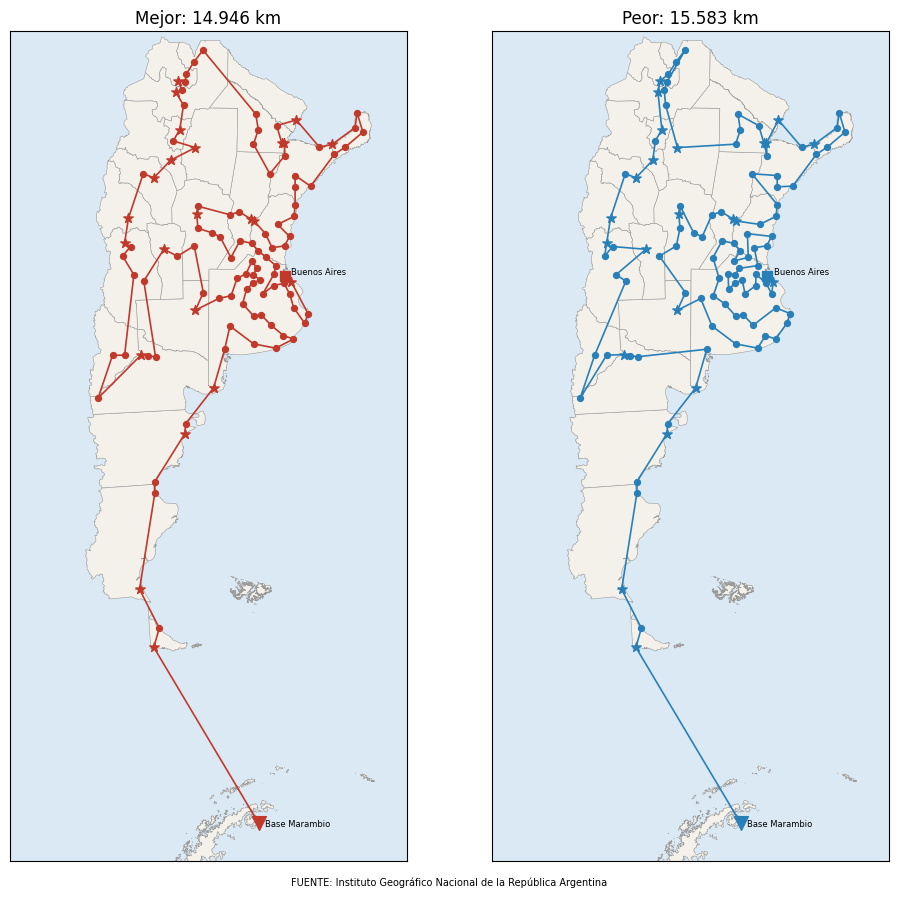

In [11]:
gira.plot_tours(
    cities, {"Mejor": results[0][1], "Peor": results[-1][1]}, city_distances
)

Las dos giras recorren el país de forma ordenada, sin cruces a la vista, pero la diferencia entre ellas son cientos de km de avioneta. Con 111 ciudades hay muchísimos mínimos locales, y cada ejecución de gradiente descendente cae en el primero que encuentra.

---
## El cartel de la gira

El manager no quiere esperar más: se queda con la mejor gira que encontramos y manda a imprimir los carteles:

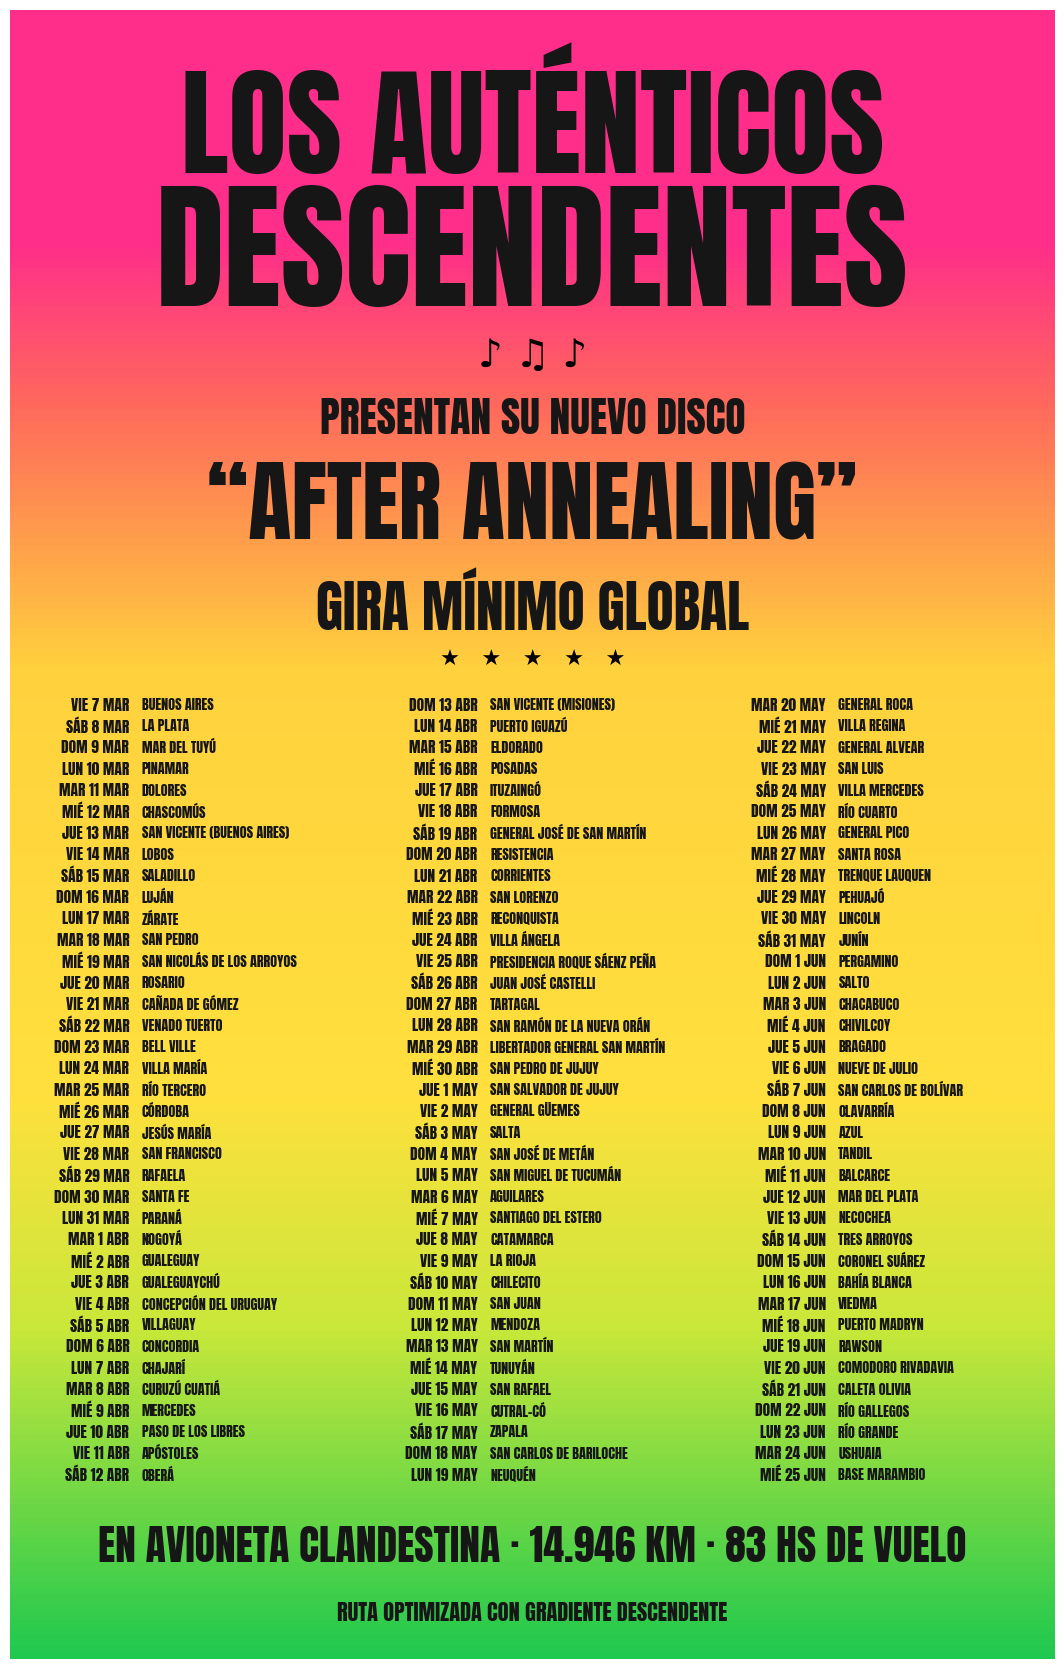

In [12]:
gira.plot_poster(
    cities,
    results[0][1],
    city_distances,
    footer="Ruta optimizada con gradiente descendente",
)

Casi cuatro meses de gira, 111 shows sin un solo día de descanso y más de 80 horas arriba de la avioneta. Nadie dijo que bajar por el gradiente fuera fácil.

Justo cuando salen de la imprenta los primeros carteles, le avisamos al manager que hay otro algoritmo que quizás encuentre una gira más corta. Gradiente descendente se queda atrapado en el primer mínimo local que encuentra, y para escapar de él tendría que aceptar, de vez en cuando, moverse a una gira peor, con la esperanza de llegar después a una mejor. Esa es la idea de **Simulated Annealing**, que vemos en la próxima notebook. El manager no está muy contento, pero acepta esperar.

> 🧠 **Nota**: Las funciones `gradient_descent()` y `stochastic_gradient_descent()` también están en el archivo `search_methods.py`, para poder usarlas en las próximas notebooks.